# Pipeline completo: foto → regiones → clase (cabeza CLIP) → profundidad → gramos y macros

**Proyecto IA2 · conteo de calorías por foto**

Prueba **de punta a punta** el sistema con lo que ya tienes: SegFormer‑B1 (regiones), la **cabeza CLIP nueva** (clase de cada región, sin metadata), el **DPT** de profundidad y la **cabeza nutricional** (gramos por región). Compara contra los totales reales de Nutrition5k (masa, kcal, grasa, carbohidratos, proteína).

```
foto RGB ─► B1 (regiones por clase) ─► CLIP + cabeza A (clase de cada región) ─┐
   └─────► DPT (profundidad en metros) ─► altura / volumen por región ─────────┼─► cabeza nutricional ─► gramos por región
                                                                               │         │
                                   tabla nutricional real (ingredients_metadata) ◄─────────┘ ─► kcal, grasa, carb, proteína
```

### Qué mide este notebook y por qué es honesto
- **Test solo con platos que ninguna etapa vio:** la cabeza de clasificación se entrenó con los platos de `dataset_A/B` (train/val). Aquí **no se usan** ni para entrenar ni para evaluar la cabeza nutricional. Se usa el resto del dataset (los "pendientes") y el **set limpio**.
- **Seis variantes** que aíslan de dónde viene el error (clase, profundidad, densidad), en la Parte 7.
- **Optimistas marcados:** la variante con profundidad real (`depth_raw.png`) es una cota superior, no una cifra de producto.

---

## Qué debe haber en tu carpeta

**Junto a este notebook** (los produjeron los notebooks anteriores):

| Qué | De dónde sale | Para qué |
|---|---|---|
| `cabeza_clip_A_s0.pt`, `_s1.pt`, `_s2.pt` | notebook de fine‑tuning (Parte 6) | clase de cada región (se promedian las 3 semillas) |
| `dataset_A_minimo/manifest.csv` y `dataset_B_estricto/manifest.csv` | exportación del autoetiquetado | saber qué platos vio la cabeza de clasificación (**solo el manifest**, no hacen falta los PNG) |
| `clean_refs/manifest.csv` | export de referencias limpias | identificar los platos del set limpio |

**Fuera de la carpeta, en las rutas de la configuración:**

| Qué | Ruta por defecto |
|---|---|
| `dish_metadata_cafe1.csv`, `dish_metadata_cafe2.csv`, **`ingredients_metadata.csv`** | `C:\nutrition5k\metadata\` |
| `realsense_overhead\<plato>\rgb.png` (y `depth_raw.png` para la variante de cota superior) | `C:\nutrition5k\realsense_overhead\` |
| SegFormer‑B1 (`config.json` + `model.safetensors`) | `C:\foodseg_segformer\mit-b1\` |
| `depth_model_final.pt` **y `depth_inference.py` en la misma carpeta** | `C:\nutrition5k\depth_finetune\` |
| CLIP‑L/14 y `Intel/dpt-hybrid-midas` | caché de Hugging Face (se descargan la primera vez) |
| *(opcional, recomendado)* lista de platos con los que entrenaste el DPT (json o txt) | `DPT_SPLIT_FILE` |

**No hace falta:** los `.npz` del autoetiquetado, SAM2, `cache_ft/`, ni el checkpoint de la cabeza nutricional anterior (tenía otras clases, así que aquí se reentrena; tarda minutos).

Se crea `pipeline_cache/` con las extracciones por tandas. Si se interrumpe, al volver a correr **continúa donde se quedó**.


## 1. Configuración


In [1]:
from pathlib import Path
import csv, json, time, math, random, warnings, hashlib, sys
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from PIL import Image

# ============ 🔧 RUTAS (ajústalas a tu PC) ============
N5K_ROOT   = Path(r"C:\nutrition5k")                                  # contiene metadata/ y realsense_overhead/
SEG_DIR    = Path(r"C:\foodseg_segformer\mit-b1")                     # SegFormer-B1 (FoodSeg103)
DEPTH_CKPT = Path(r"C:\nutrition5k\depth_finetune\depth_model_final.pt")
DEPTH_INFER_DIR = DEPTH_CKPT.parent                                    # carpeta donde está depth_inference.py
HEAD_DIR   = Path(".")                                                 # donde están cabeza_clip_*.pt
HEAD_TAG   = "A"                                                       # "A" o "B" (la que elijas tras el bootstrap)
HEAD_FILES = [HEAD_DIR / f"cabeza_clip_{HEAD_TAG}_s{s}.pt" for s in (0, 1, 2)]
MANIFESTS  = [Path("dataset_A_minimo/manifest.csv"), Path("dataset_B_estricto/manifest.csv")]
REFS_MANIFEST  = Path("clean_refs/manifest.csv")
DPT_SPLIT_FILE = None        # 🔧 opcional: json/txt con los platos que vio el DPT al entrenar (ver Parte 2)
CACHE_DIR  = Path("pipeline_cache"); CACHE_DIR.mkdir(exist_ok=True)

# ============ GEOMETRÍA / REGIONES ============
S             = 128          # rejilla común donde se calculan las features
SEG_INPUT     = 512          # entrada del SegFormer
SEG_MEAN, SEG_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
MIN_REGION_PX = 1500         # área mínima de región en la imagen original (igual que al entrenar la cabeza CLIP)
R_MAX         = 16           # máximo de regiones por plato (se conservan las más grandes)
BG_ID         = 0            # fondo en FoodSeg103
IGNORE        = 255
DEPTH_UNIT    = 1e-4         # depth_raw.png -> metros
DEPTH_MAX_M   = 0.6
CLIP_CHUNK    = 16
CHUNK         = 250          # platos por tanda de extracción (cada tanda se guarda sola)

DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
SEED    = 42
SEEDS   = [0, 1, 2]
MAX_DISHES = None            # p. ej. 60 para una prueba rápida de todo el notebook
TARGETS = ["mass", "kcal", "fat", "carb", "protein"]
UNITS   = ["g", "kcal", "g", "g", "g"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("device:", DEVICE)


device: cuda


## 2. Metadata y selección de platos

Se leen los **totales por plato** (las etiquetas) y se arman los grupos:

- **Vistos por la cabeza CLIP:** platos en `train`/`val` de A o B. **No se usan aquí.**
- **Pendientes (U):** el resto. Con ellos se entrena y valida la cabeza nutricional (80/10 %) y el 10 % restante es test.
- **Set limpio:** solo test (nunca entrena).

**Profundidad:** el DPT se fine‑tuneó con parte de Nutrition5k, y en esos platos su profundidad es mejor que en fotos nuevas. Si tienes la lista de platos que usó para entrenar, pásala en `DPT_SPLIT_FILE` (json con listas por split —se ignoran las claves que contengan "test"— o un txt con un plato por línea) y el notebook reporta también el test **solo sobre platos que el DPT no vio**.


In [2]:
def load_metadata(meta_dir):
    rows = []
    for fn in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
        p = meta_dir / fn
        if not p.exists():
            warnings.warn(f"no existe {p}"); continue
        with open(p, newline="", encoding="utf-8") as f:
            for r in csv.reader(f):
                if len(r) < 6: continue
                try:
                    dish, kcal, mass, fat, carb, prot = r[0], *[float(x) for x in r[1:6]]
                except ValueError:
                    continue
                rows.append([dish, mass, kcal, fat, carb, prot])          # reordeno a TARGETS
    return pd.DataFrame(rows, columns=["dish_id"] + TARGETS)

def load_dpt_seen(path):
    if path is None: return None
    path = Path(path); txt = path.read_text(encoding="utf-8")
    try:
        obj = json.loads(txt)
    except json.JSONDecodeError:
        return {l.strip() for l in txt.splitlines() if l.strip()}
    if isinstance(obj, dict):
        ids = set()
        for k, v in obj.items():
            if "test" not in k.lower() and isinstance(v, (list, tuple)):
                ids |= {str(x) for x in v}
        return ids
    return {str(x) for x in obj}

def make_splits(n_u, n_refs, seed=SEED, fr=(0.8, 0.1)):
    """Los n_u primeros platos son 'pendientes' (train/val/test al azar); los n_refs últimos (set limpio) solo van a test."""
    perm = np.random.default_rng(seed).permutation(n_u)
    a, b = int(n_u * fr[0]), int(n_u * (fr[0] + fr[1]))
    idx = dict(train=perm[:a], val=perm[a:b], test=np.r_[perm[b:], np.arange(n_u, n_u + n_refs)])
    grp = np.array(["u"] * n_u + ["refs"] * n_refs)
    return idx, grp

img_root = N5K_ROOT / "realsense_overhead"
df = load_metadata(N5K_ROOT / "metadata")
have = {p.name for p in img_root.iterdir() if (p / "rgb.png").exists()}
df = df[df.dish_id.isin(have) & (df.mass > 5)].drop_duplicates("dish_id").reset_index(drop=True)
ratio = (df.kcal / df.mass).median()
assert 0.3 < ratio < 5, f"kcal/masa mediana = {ratio:.2f}: revisa el orden de columnas del CSV"

seen = set()
for m in MANIFESTS:
    man = pd.read_csv(m, keep_default_na=False, dtype=str)
    seen |= set(man[man.split.isin(["train", "val"])].dish)
refs = pd.read_csv(REFS_MANIFEST, keep_default_na=False, dtype=str)
REF_SET = set(refs.dish)
assert not (seen & REF_SET), "hay platos del set limpio en train/val de la cabeza CLIP"

pool_u   = [d for d in df.dish_id if d not in seen and d not in REF_SET]
pool_ref = [d for d in df.dish_id if d in REF_SET]
if MAX_DISHES:
    pool_u, pool_ref = pool_u[:MAX_DISHES], pool_ref[:20]
dishes = pool_u + pool_ref
KEY = hashlib.md5(",".join(dishes).encode()).hexdigest()[:8]               # identifica esta lista de platos en la caché

IDX, GRP = make_splits(len(pool_u), len(pool_ref))
Y = df.set_index("dish_id").loc[dishes, TARGETS].values.astype(np.float32)

DPT_SEEN = load_dpt_seen(DPT_SPLIT_FILE)
DPT_SEEN_ARR = np.array([d in DPT_SEEN for d in dishes]) if DPT_SEEN is not None else None

print(f"{len(df)} platos con imagen y metadata | kcal/g mediana = {ratio:.2f}")
print(f"vistos por la cabeza CLIP (excluidos): {len(seen)} | pendientes U: {len(pool_u)} | set limpio: {len(pool_ref)}")
print({k: len(v) for k, v in IDX.items()}, "| (test incluye el set limpio)")
if DPT_SEEN_ARR is not None:
    te = IDX["test"]
    print(f"DPT: {int(DPT_SEEN_ARR.sum())} de {len(dishes)} platos los vio al entrenar | test que el DPT no vio: {int((~DPT_SEEN_ARR[te]).sum())}")
else:
    print("⚠ sin DPT_SPLIT_FILE: el test puede incluir platos con los que se entrenó el DPT (profundidad algo optimista).")


3485 platos con imagen y metadata | kcal/g mediana = 1.05
vistos por la cabeza CLIP (excluidos): 1242 | pendientes U: 2203 | set limpio: 40
{'train': 1762, 'val': 220, 'test': 261} | (test incluye el set limpio)
⚠ sin DPT_SPLIT_FILE: el test puede incluir platos con los que se entrenó el DPT (profundidad algo optimista).


## 3. Los modelos como adaptadores (todos congelados)

- **B1:** de la foto saca (a) las probabilidades en la rejilla de 128×128 y (b) el mapa de clases a resolución original, del que salen las **regiones** (componentes conectados de cada clase, ≥ `MIN_REGION_PX`).
- **CLIP + cabeza:** embedding de cada región (**mismo formato con el que se entrenó la cabeza**: media del recorte enmascarado y de la caja completa, cuadrados, relleno gris) y probabilidades de clase **promediadas sobre las 3 semillas**. Se pasa la distribución completa (no solo la clase ganadora), así que la cabeza nutricional ve la incertidumbre.
- **DPT:** profundidad en metros con `depth_inference.py`.

El vocabulario de clases sale del propio `.pt` de la cabeza.


In [3]:
from transformers import SegformerForSemanticSegmentation, CLIPModel, CLIPProcessor

# ---------- Cabeza(s) CLIP: clases y pesos ----------
HEAD_CKS = [torch.load(f, map_location="cpu", weights_only=False) for f in HEAD_FILES]
CLASSES = HEAD_CKS[0]["classes"]                  # ["background", clase1, ..., claseK]
K = len(CLASSES) - 1
assert all(ck["classes"] == CLASSES for ck in HEAD_CKS), "las cabezas tienen clases distintas"
CLIP_NAME = HEAD_CKS[0]["clip_name"]
HEADS_WB = [(ck["linear"]["weight"].float().to(DEVICE), ck["linear"]["bias"].float().to(DEVICE)) for ck in HEAD_CKS]
print(f"{len(HEAD_CKS)} cabezas | {K} clases | CLIP: {CLIP_NAME}")

# ---------- SegFormer-B1 ----------
seg_model = SegformerForSemanticSegmentation.from_pretrained(str(SEG_DIR)).to(DEVICE).eval()
for p in seg_model.parameters(): p.requires_grad_(False)
C_SEG = seg_model.config.num_labels
id2label = {int(k): v for k, v in seg_model.config.id2label.items()}
SEG_MEAN_T = torch.tensor(SEG_MEAN, device=DEVICE).view(1, 3, 1, 1)
SEG_STD_T  = torch.tensor(SEG_STD,  device=DEVICE).view(1, 3, 1, 1)
print("clases del segmentador:", C_SEG, "| fondo:", id2label.get(BG_ID))

# ---------- CLIP ----------
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_proc  = CLIPProcessor.from_pretrained(CLIP_NAME)
clip_dtype = next(clip_model.parameters()).dtype
CLIP_DIM   = clip_model.config.projection_dim
_DUMMY_TXT = clip_proc(text=["a"], return_tensors="pt", padding=True).to(DEVICE)

@torch.no_grad()
def embed_crops(crops):
    feats = []
    for i in range(0, len(crops), CLIP_CHUNK):
        pv = clip_proc(images=crops[i:i + CLIP_CHUNK], return_tensors="pt")["pixel_values"]
        out = clip_model(**_DUMMY_TXT, pixel_values=pv.to(DEVICE, clip_dtype))
        feats.append(F.normalize(out.image_embeds.float(), dim=-1))
    return torch.cat(feats) if feats else torch.zeros(0, CLIP_DIM, device=DEVICE)

def make_crop(img, mask, masked=True, pad=10, square=True):
    ys, xs = np.where(mask)
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, img.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, img.shape[1])
    crop = img[y0:y1, x0:x1].copy()
    if masked:
        crop[~mask[y0:y1, x0:x1]] = 127
    if square:
        h, w = crop.shape[:2]; s = max(h, w)
        canvas = np.full((s, s, 3), 127, np.uint8)
        oy, ox = (s - h) // 2, (s - w) // 2
        canvas[oy:oy + h, ox:ox + w] = crop
        crop = canvas
    return Image.fromarray(crop)

def embed_regions(img, rm):
    """(R, CLIP_DIM) float16: media normalizada de recorte enmascarado + caja completa. rm: ids 1..R."""
    R = int(rm.max())
    if R == 0: return np.zeros((0, CLIP_DIM), np.float16)
    masks = [rm == i for i in range(1, R + 1)]
    fm = embed_crops([make_crop(img, m, masked=True) for m in masks])
    fb = embed_crops([make_crop(img, m, masked=False) for m in masks])
    return F.normalize(fm + fb, dim=-1).cpu().numpy().astype(np.float16)

@torch.no_grad()
def clip_head_probs(emb):
    """(M, CLIP_DIM) -> (M, K): softmax de cada cabeza, promediado sobre las semillas."""
    x = F.normalize(torch.from_numpy(np.asarray(emb, np.float32)).to(DEVICE), dim=-1)
    out = sum((x @ W.T + b).softmax(-1) for W, b in HEADS_WB) / len(HEADS_WB)
    return out.cpu().numpy()

# ---------- Profundidad ----------
def load_depth_model():
    if str(DEPTH_INFER_DIR) not in sys.path:
        sys.path.insert(0, str(DEPTH_INFER_DIR))
    from depth_inference import load_depth_model as _load
    return _load(str(DEPTH_CKPT), DEVICE)

DEPTH_MODEL = load_depth_model()          # (model, prior); la primera vez baja Intel/dpt-hybrid-midas de internet

@torch.no_grad()
def depth_from_pil(pil_img):
    """Foto RGB original -> profundidad en METROS reducida a SxS."""
    from depth_inference import predict_depth_m
    model, prior = DEPTH_MODEL
    dm = predict_depth_m(model, prior, pil_img)
    t = torch.from_numpy(dm.astype(np.float32))[None, None]
    return F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy()

def depth_from_gt(dish_dir):
    """depth_raw.png -> metros (inválidos rellenados con el vecino válido más cercano) reducido a SxS."""
    raw = np.array(Image.open(Path(dish_dir) / "depth_raw.png")).astype(np.float32)
    valid = (raw > 0) & (raw < 65535) & (raw * DEPTH_UNIT < DEPTH_MAX_M)
    d = raw * DEPTH_UNIT
    if valid.any() and not valid.all():
        idx = ndi.distance_transform_edt(~valid, return_distances=False, return_indices=True)
        d = d[tuple(idx)]
    elif not valid.any():
        d = np.full_like(d, 0.36)
    t = torch.from_numpy(d.astype(np.float32))[None, None]
    return F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy()


c:\Users\mjcor\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1116 15:02:16.507000 14788 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


3 cabezas | 67 clases | CLIP: openai/clip-vit-large-patch14


Loading weights: 100%|██████████| 208/208 [00:00<00:00, 1810.84it/s]


clases del segmentador: 104 | fondo: background


Loading weights: 100%|██████████| 414/414 [00:00<00:00, 19470.77it/s]


## 4. De la foto a *features por región*

Funciones **sin GPU** (se pueden probar solas):

- `components`: componentes conectados de cada clase predicha (ignora fondo).
- `top_regions`: se queda con las `R_MAX` más grandes y las numera por área descendente.
- `region_features`: por región, fracción de área y estadísticas de **altura** sobre el plano de la mesa (media, desviación, p90) más un proxy de volumen; y 5 globales del plato. `altura = plano − profundidad`, con el plano estimado como la mediana de la profundidad del fondo.

El volumen queda en unidades relativas: la cabeza nutricional aprende la escala hacia gramos.


In [4]:
GEOM_NAMES = ["area_frac", "h_mean_cm", "h_std_cm", "h_p90_cm", "vol"]
GLOB_NAMES = ["plane_cm", "food_frac", "n_regions", "h_mean_all_cm", "vol_total"]
N_GEOM, N_GLOB = len(GEOM_NAMES), len(GLOB_NAMES)

def grid_index(n_src, n_dst=S):
    return np.minimum(((np.arange(n_dst) + 0.5) * n_src / n_dst).astype(int), n_src - 1)

def components(class_map, min_px=MIN_REGION_PX):
    """Componentes conectados de cada clase (ignora 0 = fondo y 255). -> (region_map uint16, clase de origen por región)."""
    rm = np.zeros(class_map.shape, np.uint16); src = []
    for c in np.unique(class_map):
        if c == BG_ID or c == IGNORE: continue
        comp, n = ndi.label(class_map == c)
        if n == 0: continue
        areas = np.bincount(comp.ravel())[1:]
        for k in np.nonzero(areas >= min_px)[0] + 1:
            src.append(int(c)); rm[comp == k] = len(src)
    return rm, src

def top_regions(rm, src, r_max=R_MAX):
    """Conserva las r_max regiones más grandes y las renumera 1..n por área descendente."""
    if not src: return rm.astype(np.uint8), src
    areas = np.bincount(rm.ravel().astype(np.int64))[1:]
    order = np.argsort(-areas, kind="stable")[:r_max]
    new = np.zeros(rm.shape, np.uint8)
    for nid, old in enumerate(order, start=1):
        new[rm == old + 1] = nid
    return new, [src[o] for o in order]

def region_features(rm, bg, depth_m, n, r_max=R_MAX, return_height=False):
    """rm: (S,S) ids 1..n · bg: (S,S) bool (fondo según B1) · depth_m: (S,S) metros. -> G (r_max,5), M (r_max,) bool, GL (5,)"""
    H, W = rm.shape; tot = float(H * W)
    plane = np.median(depth_m[bg]) if bg.sum() >= 200 else np.percentile(depth_m, 95)
    height_cm = np.clip(plane - depth_m, 0, None) * 100.0
    G = np.zeros((r_max, N_GEOM), np.float32); M = np.zeros(r_max, bool)
    for r in range(min(n, r_max)):
        m = rm == r + 1
        if not m.any(): continue
        h = height_cm[m]
        G[r] = [m.sum() / tot, h.mean(), h.std(), np.percentile(h, 90), h.sum() / tot]; M[r] = True
    food = rm > 0
    GL = np.array([plane * 100.0, food.mean(), n / r_max,
                   height_cm[food].mean() if food.any() else 0.0,
                   height_cm[food].sum() / tot], np.float32)
    return (G, M, GL, height_cm) if return_height else (G, M, GL)

def load_density_table(meta_dir, class_names):
    """Densidad por gramo [kcal, grasa, carb, prot] de cada clase, buscando su nombre en ingredients_metadata.csv. NaN si no está."""
    ing = pd.read_csv(Path(meta_dir) / "ingredients_metadata.csv")
    cols = {c.strip().lower(): c for c in ing.columns}
    pick = lambda pref: next(cols[c] for c in cols if c.startswith(pref))
    name_c, cal_c, fat_c, carb_c, prot_c = pick("ingr"), pick("cal"), pick("fat"), pick("carb"), pick("prot")
    t = ing.assign(_n=ing[name_c].astype(str).str.strip().str.lower()).drop_duplicates("_n").set_index("_n")
    rows = []
    for n in class_names:
        k = n.strip().lower()
        rows.append([float(t.loc[k, cal_c]), float(t.loc[k, fat_c]), float(t.loc[k, carb_c]), float(t.loc[k, prot_c])]
                    if k in t.index else [np.nan] * 4)
    return np.array(rows, np.float32)


## 5. Extracción con caché por tandas

Dos etapas independientes, cada una guardada en `pipeline_cache/` en tandas de `CHUNK` platos (si se corta, continúa):

- **Etapa A (B1 + CLIP):** regiones a rejilla 128, fondo, embedding CLIP de cada región y probabilidades de B1 por región (para la variante "pipeline anterior").
- **Etapa B (profundidad):** mapa 128×128 en metros, **del DPT** y **real** (`depth_raw.png`, cota superior).

Las probabilidades de la cabeza CLIP no se cachean: se calculan al instante desde los embeddings.


In [5]:
def load_rgb(dish):
    return np.array(Image.open(img_root / dish / "rgb.png").convert("RGB"))

@torch.no_grad()
def b1_forward(img):
    """-> probs (C,S,S) y mapa de clases a resolución original (uint8, 0 = fondo)."""
    H, W = img.shape[:2]
    x = torch.from_numpy(np.array(Image.fromarray(img).resize((SEG_INPUT, SEG_INPUT), Image.BILINEAR)))
    x = (x.to(DEVICE).permute(2, 0, 1)[None].float() / 255.0 - SEG_MEAN_T) / SEG_STD_T
    lg = seg_model(pixel_values=x).logits
    if lg.shape[-1] != S:
        lg = F.interpolate(lg, size=(S, S), mode="bilinear", align_corners=False)
    probs = lg.softmax(1)[0].cpu().numpy()
    full = F.interpolate(lg, size=(H, W), mode="bilinear", align_corners=False).argmax(1)[0].cpu().numpy().astype(np.uint8)
    return probs, full

def stage_a(img):
    probs, full = b1_forward(img)
    rm, src = components(full)
    rm, src = top_regions(rm, src)
    n = len(src); H, W = img.shape[:2]
    emb = np.zeros((R_MAX, CLIP_DIM), np.float16)
    if n: emb[:n] = embed_regions(img, rm)
    rm128 = rm[np.ix_(grid_index(H), grid_index(W))]
    pb1 = np.zeros((R_MAX, probs.shape[0]), np.float16)
    for r in range(n):
        m = rm128 == r + 1
        if m.any(): pb1[r] = probs[:, m].mean(1)
    return dict(rm=rm128.astype(np.uint8), bg=probs.argmax(0) == BG_ID, emb=emb, n=n, pb1=pb1)

def stage_a_chunk(ids):
    outs = [stage_a(load_rgb(d)) for d in ids]
    return {k: np.stack([o[k] for o in outs]) for k in ("rm", "bg", "emb", "n", "pb1")}

def depth_chunk(mode):
    def fn(ids):
        if mode == "gt":
            return dict(depth=np.stack([depth_from_gt(img_root / d) for d in ids]))
        return dict(depth=np.stack([depth_from_pil(Image.open(img_root / d / "rgb.png").convert("RGB")) for d in ids]))
    return fn

def cached_chunks(name, dish_list, fn, chunk=CHUNK):
    d = CACHE_DIR / f"{name}_{KEY}"; d.mkdir(parents=True, exist_ok=True)
    parts, t0 = [], time.time()
    for ci, i in enumerate(range(0, len(dish_list), chunk)):
        f = d / f"chunk_{ci:04d}.npz"
        if not f.exists():
            np.savez_compressed(f, **fn(dish_list[i:i + chunk]))
            print(f"  {name}: {min(i + chunk, len(dish_list))}/{len(dish_list)}  ({time.time() - t0:.0f} s)")
        z = np.load(f); parts.append({k: z[k] for k in z.files})
    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}

A      = cached_chunks("stageA", dishes, stage_a_chunk)
DEPTH  = {"model": cached_chunks("depth_model", dishes, depth_chunk("model"))["depth"],
          "gt":    cached_chunks("depth_gt",    dishes, depth_chunk("gt"))["depth"]}
print("regiones por plato: media %.1f, máx %d, platos sin regiones: %d" % (A["n"].mean(), A["n"].max(), (A["n"] == 0).sum()))
for k, v in DEPTH.items():
    print(f"profundidad {k}: mediana {np.median(v):.3f} m (esperado ~0.30-0.40)")


regiones por plato: media 3.9, máx 16, platos sin regiones: 10
profundidad model: mediana 0.366 m (esperado ~0.30-0.40)
profundidad gt: mediana 0.361 m (esperado ~0.30-0.40)


## 6. Features por variante

- **Geometría** (altura, volumen): una con la profundidad del DPT y otra con la real.
- **Clases `P` por región:** (a) la **cabeza CLIP** (K clases, sin fondo) o (b) las probabilidades de **B1** (104 clases de FoodSeg103, el pipeline anterior).
- **Tabla nutricional real:** densidad por gramo (kcal, grasa, carb, proteína) de cada clase desde `ingredients_metadata.csv`, por nombre. Las clases que no se encuentren usan la razón global del dataset y se listan aquí abajo.


In [6]:
def build_geometry(depth):
    n_d = len(dishes); G = np.zeros((n_d, R_MAX, N_GEOM), np.float32)
    M = np.zeros((n_d, R_MAX), bool); GL = np.zeros((n_d, N_GLOB), np.float32)
    for i in range(n_d):
        G[i], M[i], GL[i] = region_features(A["rm"][i], A["bg"][i], depth[i], int(A["n"][i]))
    return G, M, GL

GEO = {k: build_geometry(v) for k, v in DEPTH.items()}
M_ALL = GEO["model"][1]
assert (GEO["gt"][1] == M_ALL).all(), "las máscaras de región no dependen de la profundidad"

# clases: cabeza CLIP (K) y B1 (104), enmascaradas por las regiones válidas
P_head = np.zeros((len(dishes), R_MAX, K), np.float16)
P_head[M_ALL] = clip_head_probs(A["emb"][M_ALL]).astype(np.float16)
P_b1 = (A["pb1"] * M_ALL[..., None]).astype(np.float16)
PCLS = {"head": P_head, "b1": P_b1}

# tabla nutricional real; las clases sin coincidencia usan la razón global de los platos de entrenamiento
tab = load_density_table(N5K_ROOT / "metadata", CLASSES[1:])
tr = IDX["train"]
PRIOR_GLOBAL = (Y[tr, 1:].sum(0) / Y[tr, 0].sum()).astype(np.float32)
miss = np.isnan(tab[:, 0])
DENS_TABLE = np.where(np.isnan(tab), PRIOR_GLOBAL[None, :], tab).astype(np.float32)
print(f"tabla nutricional: {K - int(miss.sum())}/{K} clases encontradas por nombre | razón global: {np.round(PRIOR_GLOBAL, 3)}")
if miss.any():
    print("sin coincidencia (usan la razón global):", [CLASSES[1 + i] for i in np.nonzero(miss)[0]])
print("kcal/g de la tabla: min %.2f, mediana %.2f, max %.2f" % (DENS_TABLE[:, 0].min(), np.median(DENS_TABLE[:, 0]), DENS_TABLE[:, 0].max()))


tabla nutricional: 65/67 clases encontradas por nombre | razón global: [1.119 0.056 0.086 0.077]
sin coincidencia (usan la razón global): ['', 'leafy greens']
kcal/g de la tabla: min 0.10, mediana 0.91, max 5.78


## 7. La cabeza nutricional (Deep Sets) y las seis variantes

Misma idea del notebook anterior: **gramos por región ≥ 0**, y los totales del plato son la **suma sobre regiones**, que es lo único que Nutrition5k etiqueta. Cambia la densidad nutricional, con tres modos:

| Modo | Densidad por gramo de una región |
|---|---|
| `learned` | tabla **aprendida** (como antes): `(P · exp(T)) · prior` |
| `table` | tabla **real fija**: `P · tabla` (la cabeza solo aprende los gramos) |
| `table_ft` | tabla real con un **ajuste multiplicativo aprendido** y regularizado |

**Variantes**, pensadas para aislar el origen del error:

1. B1 · profundidad DPT · densidad aprendida → *el pipeline anterior, reentrenado en este split*.
2. CLIP · **sin** profundidad · tabla → ¿cuánto aporta la profundidad?
3. CLIP · DPT · aprendida
4. CLIP · DPT · tabla → *la candidata a producto*
5. CLIP · DPT · tabla + ajuste
6. CLIP · profundidad **real** · tabla → *cota superior (no es una cifra de producto)*

Comparaciones clave: (1 → 3) efecto de la cabeza CLIP · (2 → 4) efecto de la profundidad · (3 → 4) tabla real frente a aprendida · (4 → 6) costo de usar profundidad predicha.


In [7]:
class NutritionHead(nn.Module):
    def __init__(self, n_classes, prior, hidden=128, emb=32, drop=0.1, use_depth=True, mass_scale=100.0,
                 dens_mode="learned", table=None):
        super().__init__()
        self.cls_emb = nn.Linear(n_classes, emb, bias=False)
        self.enc = nn.Sequential(
            nn.Linear(emb + N_GEOM + N_GLOB, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, hidden), nn.GELU(),
            nn.Linear(hidden, 1))
        self.dens_mode = dens_mode
        if dens_mode in ("learned", "table_ft"):
            self.log_dens = nn.Parameter(torch.zeros(n_classes, 4))
        if dens_mode in ("table", "table_ft"):
            self.register_buffer("table", torch.as_tensor(table, dtype=torch.float32))
        self.register_buffer("prior", torch.as_tensor(prior, dtype=torch.float32))      # (4,) por gramo
        self.mass_scale = mass_scale
        gkeep  = torch.tensor([1, 0, 0, 0, 0], dtype=torch.float32) if not use_depth else torch.ones(N_GEOM)
        glkeep = torch.tensor([0, 1, 1, 0, 0], dtype=torch.float32) if not use_depth else torch.ones(N_GLOB)
        self.register_buffer("gkeep", gkeep); self.register_buffer("glkeep", glkeep)

    def densities(self):
        if self.dens_mode == "learned": return torch.exp(self.log_dens) * self.prior
        if self.dens_mode == "table":   return self.table
        return self.table * torch.exp(self.log_dens)

    def forward(self, P, G, GL, M):
        e = self.cls_emb(P)
        g = GL[:, None, :].expand(-1, P.size(1), -1) * self.glkeep
        h = torch.cat([e, G * self.gkeep, g], dim=-1)
        grams = F.softplus(self.enc(h).squeeze(-1)) * self.mass_scale * M
        dens = P @ self.densities()                                                  # (B,R,4) por gramo
        macros = (grams[..., None] * dens).sum(1)
        total = torch.cat([grams.sum(1, keepdim=True), macros], dim=1)               # [masa, kcal, grasa, carb, prot]
        return dict(total=total, grams=grams, dens=dens)

CFG = dict(hidden=128, emb=32, drop=0.1, lr=2e-3, wd=1e-3, bs=64, epochs=150, patience=25, dens_reg=1e-2, ft_reg=1e-1)

def fit_norm(cache, tr_idx):
    G, M, GL, Yt = cache["G"][tr_idx], cache["M"][tr_idx], cache["GL"][tr_idx], cache["Y"][tr_idx]
    gv = G[M]
    prior = (Yt[:, 1:].sum(0) / Yt[:, 0].sum()).astype(np.float32)
    return dict(g_mean=gv.mean(0), g_std=np.maximum(gv.std(0), 1e-6), gl_mean=GL.mean(0), gl_std=np.maximum(GL.std(0), 1e-6),
                y_scale=Yt.mean(0).astype(np.float32), prior=prior)

def apply_norm(P, G, M, GL, norm):
    Gn = (G - norm["g_mean"]) / norm["g_std"] * M[..., None]
    GLn = (GL - norm["gl_mean"]) / norm["gl_std"]
    return P.astype(np.float32), Gn.astype(np.float32), M.astype(np.float32), GLn.astype(np.float32)

def to_tensors(cache, idx, norm):
    P, G, M, GL = apply_norm(cache["P"][idx], cache["G"][idx], cache["M"][idx], cache["GL"][idx], norm)
    t = lambda a: torch.from_numpy(a).to(DEVICE)
    return dict(P=t(P), G=t(G), M=t(M), GL=t(GL), Y=t(cache["Y"][idx]))

def metrics(y, yhat):
    mae = np.abs(y - yhat).mean(0)
    return dict(mae=mae, pct=mae / y.mean(0) * 100.0)

@torch.no_grad()
def predict_tensors(model, T):
    model.eval()
    return model(T["P"], T["G"], T["GL"], T["M"])["total"].cpu().numpy()

def train_nutrition(Ttr, Tva, norm, n_classes, cfg=CFG, use_depth=True, dens_mode="learned", table=None, seed=SEED):
    set_seed(seed)
    model = NutritionHead(n_classes, norm["prior"], cfg["hidden"], cfg["emb"], cfg["drop"], use_depth, dens_mode=dens_mode, table=table).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    ys = torch.as_tensor(norm["y_scale"], device=DEVICE)
    reg_w = cfg["dens_reg"] if dens_mode == "learned" else cfg["ft_reg"]
    n = Ttr["P"].shape[0]; best, best_state, bad = 1e9, None, 0
    for ep in range(cfg["epochs"]):
        model.train(); perm = torch.randperm(n, device=DEVICE)
        for b in range(0, n, cfg["bs"]):
            ix = perm[b:b + cfg["bs"]]
            out = model(Ttr["P"][ix], Ttr["G"][ix], Ttr["GL"][ix], Ttr["M"][ix])
            loss = F.l1_loss(out["total"] / ys, Ttr["Y"][ix] / ys)
            if hasattr(model, "log_dens"):
                loss = loss + reg_w * (model.log_dens ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        val = metrics(Tva["Y"].cpu().numpy(), predict_tensors(model, Tva))["pct"].mean()
        if val < best - 1e-3:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if bad >= cfg["patience"]: break
    model.load_state_dict(best_state)
    return model, best


In [8]:
EXPERIMENTS = [
    ("1. B1 · DPT · aprendida (pipeline anterior)", dict(cls="b1",   depth="model", dens="learned")),
    ("2. CLIP · sin profundidad · tabla",           dict(cls="head", depth="none",  dens="table")),
    ("3. CLIP · DPT · aprendida",                   dict(cls="head", depth="model", dens="learned")),
    ("4. CLIP · DPT · tabla",                       dict(cls="head", depth="model", dens="table")),
    ("5. CLIP · DPT · tabla + ajuste",              dict(cls="head", depth="model", dens="table_ft")),
    ("6. CLIP · prof. real · tabla (cota superior)", dict(cls="head", depth="gt",    dens="table")),
]

def make_cache(cls, depth):
    G, M, GL = GEO["gt" if depth == "gt" else "model"]
    return dict(P=PCLS[cls], G=G, M=M, GL=GL, Y=Y)

def run_variant(cls, depth, dens):
    cache = make_cache(cls, depth)
    norm = fit_norm(cache, IDX["train"])
    T = {k: to_tensors(cache, IDX[k], norm) for k in IDX}
    C = cache["P"].shape[-1]
    runs = []
    for s in SEEDS:
        model, best = train_nutrition(T["train"], T["val"], norm, C, CFG, use_depth=(depth != "none"), dens_mode=dens,
                                      table=DENS_TABLE if cls == "head" else None, seed=s)
        runs.append(dict(seed=s, val=best, pred=predict_tensors(model, T["test"]), model=model, norm=norm))
    return runs

RESULTS = {}
t0 = time.time()
for name, kw in EXPERIMENTS:
    RESULTS[name] = run_variant(**kw)
    print(f"{name}: val %MAE {np.mean([r['val'] for r in RESULTS[name]]):.2f} ({time.time() - t0:.0f} s)")


1. B1 · DPT · aprendida (pipeline anterior): val %MAE 36.89 (49 s)
2. CLIP · sin profundidad · tabla: val %MAE 30.80 (64 s)
3. CLIP · DPT · aprendida: val %MAE 31.58 (108 s)
4. CLIP · DPT · tabla: val %MAE 30.91 (126 s)
5. CLIP · DPT · tabla + ajuste: val %MAE 29.93 (147 s)
6. CLIP · prof. real · tabla (cota superior): val %MAE 28.05 (180 s)


## 8. Resultados

**%MAE en test** (error absoluto medio relativo a la media del target; menor es mejor), promedio ± desviación entre las 3 semillas. Se muestra por subconjunto:

- **test completo:** pendientes de test + set limpio.
- **solo set limpio:** los platos anotados a mano (pocos: ruidoso).
- **DPT no lo vio:** solo si diste `DPT_SPLIT_FILE`. **Es el más honesto para la profundidad.**

Los baselines (media y ridge sobre agregados del plato) dicen si la cabeza vale la pena.


In [9]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

YTE = Y[IDX["test"]]
def subset_masks():
    te = IDX["test"]
    m = {"test completo": np.ones(len(te), bool), "solo set limpio": GRP[te] == "refs"}
    if DPT_SEEN_ARR is not None:
        m["DPT no lo vio"] = ~DPT_SEEN_ARR[te]
    return {k: v for k, v in m.items() if v.sum() > 0}

def aggregates(idx):
    G, M, GL = GEO["model"]
    return np.c_[(G[idx][..., 0] * M[idx]).sum(1), (G[idx][..., 4] * M[idx]).sum(1), GL[idx][:, 0], GL[idx][:, 3], GL[idx][:, 2]]

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(aggregates(IDX["train"]), Y[IDX["train"]])
BASE = {"Media": np.tile(Y[IDX["train"]].mean(0), (len(YTE), 1)), "Ridge (agregados)": ridge.predict(aggregates(IDX["test"]))}

def fmt(vals):
    a = np.stack(vals); return a.mean(0), a.std(0)

for sname, mask in subset_masks().items():
    rows = {}
    for k, p in BASE.items():
        rows[k] = (metrics(YTE[mask], p[mask])["pct"], np.zeros(5))
    for name, runs in RESULTS.items():
        rows[name] = fmt([metrics(YTE[mask], r["pred"][mask])["pct"] for r in runs])
    t = pd.DataFrame({k: [f"{m:.1f} ± {s:.1f}" if s > 0 else f"{m:.1f}" for m, s in zip(*v)] for k, v in rows.items()}, index=TARGETS).T
    t["promedio"] = [f"{np.mean(v[0]):.1f}" for v in rows.values()]
    print(f"\n=== %MAE · {sname} ({int(mask.sum())} platos) ===")
    display(t)



=== %MAE · test completo (261 platos) ===


,mass,kcal,fat,carb,protein,promedio
Media,55.7,71.5,87.1,68.8,89.4,74.5
Ridge (agregados),30.9,51.7,72.5,59.0,67.1,56.3
1. B1 · DPT · aprendida (pipeline anterior),27.3 ± 0.2,32.3 ± 0.6,46.1 ± 0.6,45.3 ± 0.7,45.0 ± 0.1,39.2
2. CLIP · sin profundidad · tabla,21.5 ± 0.0,29.7 ± 0.1,39.2 ± 0.3,34.4 ± 0.5,39.9 ± 0.5,32.9
3. CLIP · DPT · aprendida,25.8 ± 0.4,28.0 ± 0.4,37.5 ± 0.3,32.8 ± 0.3,36.5 ± 0.3,32.1
4. CLIP · DPT · tabla,21.9 ± 0.2,29.7 ± 0.3,38.9 ± 0.2,33.8 ± 0.3,38.5 ± 0.3,32.5
5. CLIP · DPT · tabla + ajuste,21.4 ± 0.1,29.5 ± 0.2,36.5 ± 0.2,34.1 ± 0.2,36.8 ± 0.3,31.6
6. CLIP · prof. real · tabla (cota superior),18.1 ± 0.5,24.2 ± 1.3,34.1 ± 1.3,30.2 ± 1.1,35.8 ± 0.8,28.5



=== %MAE · solo set limpio (40 platos) ===


,mass,kcal,fat,carb,protein,promedio
Media,45.7,52.4,64.3,56.8,69.2,57.7
Ridge (agregados),23.8,44.4,66.9,45.7,68.6,49.9
1. B1 · DPT · aprendida (pipeline anterior),22.1 ± 1.3,31.8 ± 0.2,52.5 ± 0.4,35.7 ± 1.1,48.4 ± 0.7,38.1
2. CLIP · sin profundidad · tabla,14.6 ± 0.2,30.2 ± 0.4,41.8 ± 0.1,27.5 ± 0.8,39.2 ± 1.3,30.7
3. CLIP · DPT · aprendida,21.2 ± 0.8,28.4 ± 0.7,40.7 ± 0.7,28.5 ± 0.4,36.1 ± 1.0,31.0
4. CLIP · DPT · tabla,16.0 ± 0.7,31.3 ± 1.2,43.3 ± 1.1,27.9 ± 0.3,39.6 ± 1.4,31.6
5. CLIP · DPT · tabla + ajuste,14.3 ± 0.1,31.4 ± 0.9,41.7 ± 1.0,28.2 ± 0.4,38.0 ± 1.2,30.7
6. CLIP · prof. real · tabla (cota superior),13.8 ± 0.6,27.9 ± 1.1,39.2 ± 1.4,26.1 ± 0.2,34.8 ± 1.5,28.3


test completo      MAE: mass 46.2 g, kcal 69.1 kcal, fat 4.4 g, carb 6.2 g, protein 6.1 g
solo set limpio    MAE: mass 50.0 g, kcal 99.1 kcal, fat 6.3 g, carb 7.6 g, protein 7.8 g


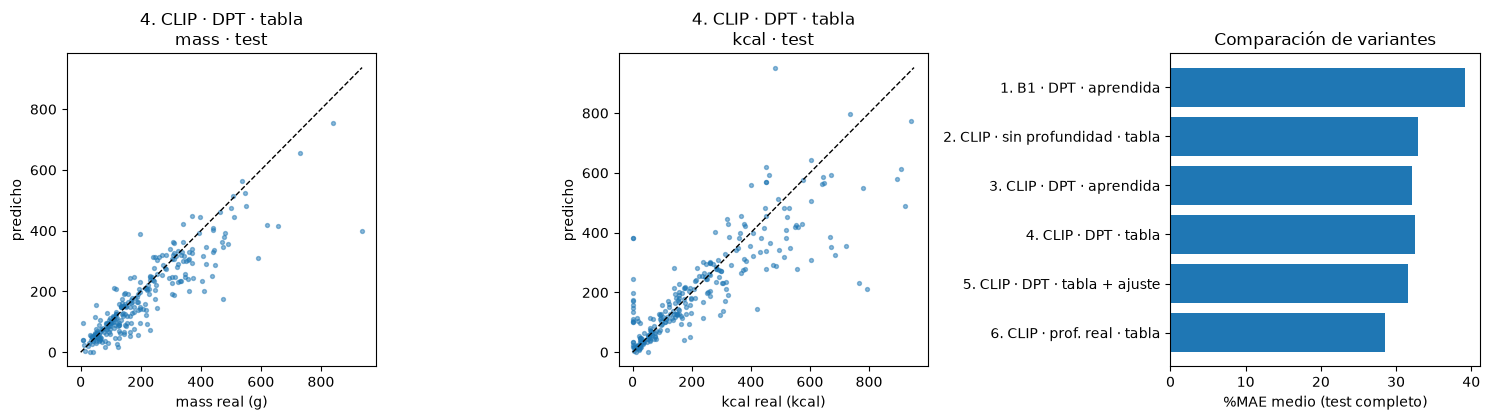

In [10]:
# MAE absoluto de la variante candidata (4), mejor semilla por validación
NAME_FINAL = "4. CLIP · DPT · tabla"
best_run = min(RESULTS[NAME_FINAL], key=lambda r: r["val"])
for sname, mask in subset_masks().items():
    mae = metrics(YTE[mask], best_run["pred"][mask])["mae"]
    print(f"{sname:18s} MAE:", ", ".join(f"{t} {m:.1f} {u}" for t, m, u in zip(TARGETS, mae, UNITS)))

yhat = best_run["pred"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, k in zip(ax[:2], [0, 1]):
    a.scatter(YTE[:, k], yhat[:, k], s=8, alpha=0.5)
    lim = max(YTE[:, k].max(), yhat[:, k].max()); a.plot([0, lim], [0, lim], "k--", lw=1)
    a.set_xlabel(f"{TARGETS[k]} real ({UNITS[k]})"); a.set_ylabel("predicho"); a.set_title(f"{NAME_FINAL}\n{TARGETS[k]} · test")
names = [n for n, _ in EXPERIMENTS]
means = [np.mean([metrics(YTE, r["pred"])["pct"].mean() for r in RESULTS[n]]) for n in names]
ax[2].barh([n.split(" (")[0] for n in names], means); ax[2].set_xlabel("%MAE medio (test completo)")
ax[2].set_title("Comparación de variantes"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()


## 9. Inferencia sobre una foto: gramos y macros por región

`predict_photo` ejecuta **todo el pipeline desde la imagen** (B1 → regiones → cabeza CLIP → DPT → cabeza nutricional) y devuelve una tabla por región con clase, probabilidad, gramos y macros, más los totales. Solo necesita la foto RGB (el caso de la app final). Con `depth_gt_dir` usa la profundidad real, para depurar.

Se usa la mejor semilla (por validación) de la variante candidata (4).


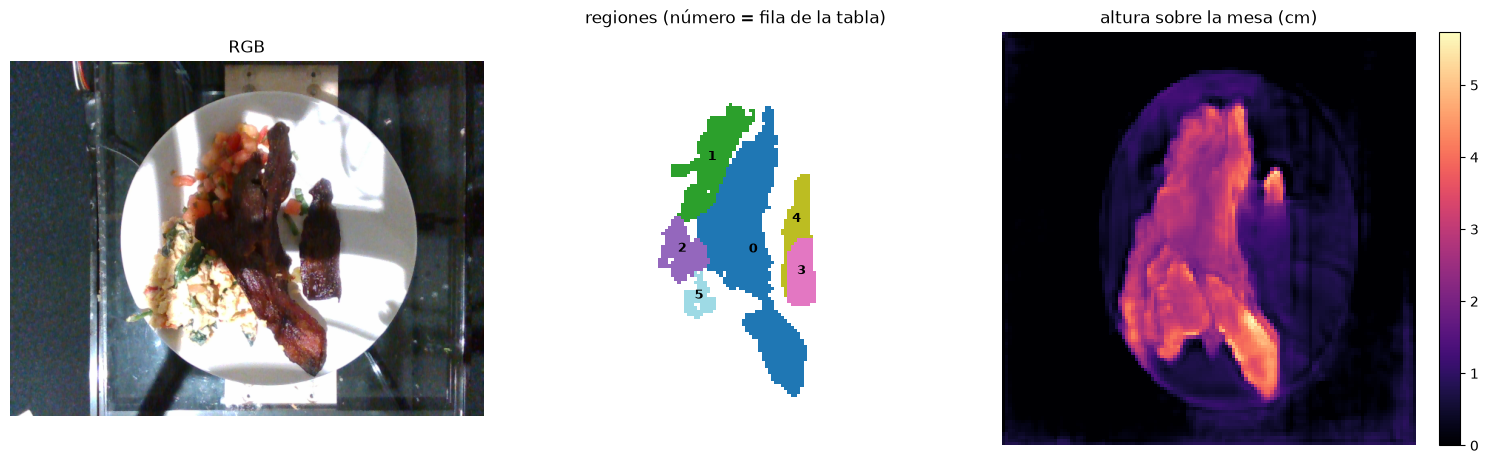

predicho: {'mass': 97.0, 'kcal': 244.10000610351562, 'fat': 17.200000762939453, 'carb': 4.599999904632568, 'protein': 18.299999237060547}
real    : {'mass': 199.0, 'kcal': 0.0, 'fat': 0.0, 'carb': 0.0, 'protein': 0.0}


,region,clase,prob_clase,area_pct,altura_cm,gramos,kcal,grasa_g,carb_g,prot_g
0,0,bacon,0.85,7.1,3.16,29.8,150.3,11.5,0.4,10.5
1,1,salsa,0.97,2.4,2.66,17.4,5.9,0.1,1.1,0.4
2,2,fish,0.18,1.2,2.67,17.8,18.4,1.2,1.0,1.8
3,3,salsa,0.20,1.0,0.92,9.2,16.9,1.0,1.1,1.0
4,4,bacon,0.35,1.0,1.94,10.7,33.4,2.3,0.4,2.7
5,5,scrambled eggs,0.24,0.5,3.01,12.2,19.2,1.1,0.5,1.9


In [11]:
FINAL = dict(model=best_run["model"], norm=best_run["norm"])

@torch.no_grad()
def predict_photo(img_path, final=FINAL, show=True, depth_gt_dir=None):
    pil = Image.open(img_path).convert("RGB"); img = np.array(pil)
    a = stage_a(img); n = a["n"]
    probs = np.zeros((R_MAX, K), np.float32)
    if n: probs[:n] = clip_head_probs(a["emb"][:n])
    depth = depth_from_gt(depth_gt_dir) if depth_gt_dir is not None else depth_from_pil(pil)
    G, M, GL, height = region_features(a["rm"], a["bg"], depth, n, return_height=True)
    probs = probs * M[:, None]

    Pn, Gn, Mn, GLn = apply_norm(probs[None], G[None], M[None], GL[None], final["norm"])
    t = lambda x: torch.from_numpy(x).to(DEVICE)
    model = final["model"].eval()
    out = model(t(Pn), t(Gn), t(GLn), t(Mn))
    grams = out["grams"][0].cpu().numpy(); dens = out["dens"][0].cpu().numpy(); total = out["total"][0].cpu().numpy()

    rows = []
    for r in range(R_MAX):
        if not M[r]: continue
        c = int(probs[r].argmax())
        rows.append(dict(region=r, clase=CLASSES[1 + c], prob_clase=round(float(probs[r, c]), 2),
                         area_pct=round(float(G[r, 0] * 100), 1), altura_cm=round(float(G[r, 1]), 2),
                         gramos=round(float(grams[r]), 1), kcal=round(float(grams[r] * dens[r, 0]), 1),
                         grasa_g=round(float(grams[r] * dens[r, 1]), 1), carb_g=round(float(grams[r] * dens[r, 2]), 1),
                         prot_g=round(float(grams[r] * dens[r, 3]), 1)))
    table = pd.DataFrame(rows)
    totals = {k: float(round(v, 1)) for k, v in zip(TARGETS, total)}

    if show:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
        ax[0].imshow(img); ax[0].set_title("RGB"); ax[0].axis("off")
        ax[1].imshow(np.ma.masked_equal(a["rm"], 0), cmap="tab20", interpolation="nearest")
        for r in range(n):
            yy, xx = np.nonzero(a["rm"] == r + 1)
            if len(yy): ax[1].text(xx.mean(), yy.mean(), str(r), color="k", ha="center", fontsize=9, weight="bold")
        ax[1].set_title("regiones (número = fila de la tabla)"); ax[1].axis("off")
        im = ax[2].imshow(height, cmap="magma"); ax[2].set_title("altura sobre la mesa (cm)"); ax[2].axis("off")
        plt.colorbar(im, ax=ax[2], fraction=0.046); plt.tight_layout(); plt.show()
    return table, totals

dish_demo = dishes[IDX["test"][-1]]                      # un plato del set limpio (nunca entrenó)
table, totals = predict_photo(img_root / dish_demo / "rgb.png")
real = {k: float(round(v, 1)) for k, v in zip(TARGETS, df.set_index("dish_id").loc[dish_demo, TARGETS])}
print("predicho:", totals); print("real    :", real)
table


## 10. Guardar el pipeline para integrarlo

El paquete incluye pesos, normalización (sin ella la cabeza falla en silencio), tabla nutricional, lista de clases y los archivos de las cabezas CLIP. **Quien lo cargue necesita además** SegFormer‑B1, el DPT, CLIP‑L/14 y los `cabeza_clip_*.pt`.


In [12]:
pkg = dict(state=best_run["model"].state_dict(), norm=best_run["norm"], cfg=CFG, dens_mode="table", table=DENS_TABLE,
           classes=CLASSES, n_classes=K, head_files=[str(f) for f in HEAD_FILES], clip_name=CLIP_NAME, targets=TARGETS,
           geometry=dict(S=S, SEG_INPUT=SEG_INPUT, MIN_REGION_PX=MIN_REGION_PX, R_MAX=R_MAX, BG_ID=BG_ID, DEPTH_UNIT=DEPTH_UNIT))
path = CACHE_DIR / "pipeline_nutricion.pt"
torch.save(pkg, path)
print("guardado:", path)

def load_nutrition_head(path=path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = NutritionHead(ck["n_classes"], ck["norm"]["prior"], ck["cfg"]["hidden"], ck["cfg"]["emb"], ck["cfg"]["drop"],
                      True, dens_mode=ck["dens_node"], table=ck["table"]).to(DEVICE)
    m.load_state_dict(ck["state"]); return m.eval(), ck["norm"], ck


guardado: pipeline_cache\pipeline_nutricion.pt


CLIP frente a B1                : -7.03 puntos de %MAE medio | IC95 [-9.71, -4.49]   (negativo = mejora)
DPT frente a sin profundidad    : -0.42 puntos de %MAE medio | IC95 [-1.15, +0.31]   (negativo = mejora)
tabla frente a aprendida        : +0.44 puntos de %MAE medio | IC95 [-1.02, +1.87]   (negativo = mejora)
tabla + ajuste frente a tabla   : -0.86 puntos de %MAE medio | IC95 [-1.37, -0.35]   (negativo = mejora)
profundidad real frente a DPT   : -4.58 puntos de %MAE medio | IC95 [-6.00, -3.18]   (negativo = mejora)

altura media por región: corr DPT-real 0.52 | sesgo -1.39 cm | MAE 1.86 cm | altura real mediana 3.23 cm
plano de la mesa: MAE 1.95 cm
corr(volumen total DPT, masa real) = 0.61
corr(volumen total real, masa real) = 0.56
corr(fracción de comida, masa real) = 0.74   <- lo único que ve la variante sin profundidad


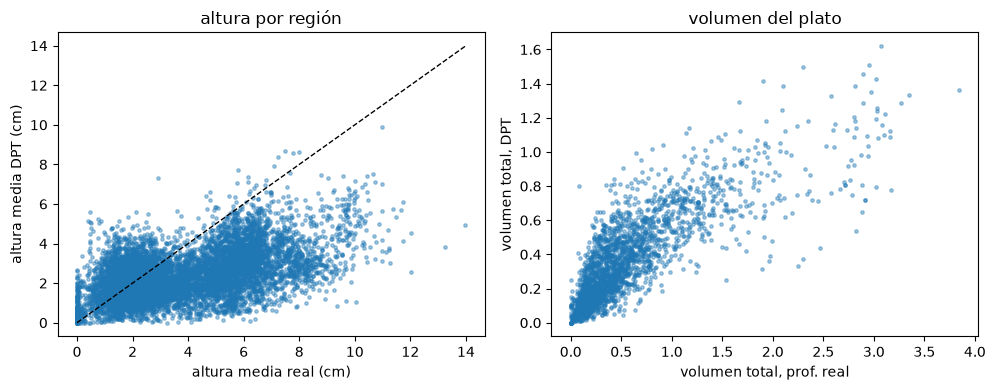


47 platos con <30 kcal reales | su predicción mediana: 33 kcal


,dish,grupo,kcal_real,kcal_pred,masa_real,masa_pred,n_reg,err_kcal,sesgo_masa_pct,error_masa_pct
203,dish_1574184971,u,0.0,383.0,50.0,156.0,4,383.0,211.0,211.0
117,dish_1574728191,u,0.0,383.0,145.0,153.0,2,383.0,6.0,6.0
260,dish_1572625810,refs,0.0,244.0,199.0,97.0,6,244.0,-51.0,51.0
87,dish_1572278894,u,0.0,198.0,61.0,37.0,2,198.0,-40.0,40.0
197,dish_1572291671,u,0.0,175.0,108.0,100.0,4,175.0,-8.0,8.0
100,dish_1573233271,u,0.0,172.0,122.0,114.0,1,172.0,-7.0,7.0
122,dish_1573232835,u,0.0,159.0,27.0,29.0,1,159.0,9.0,9.0
216,dish_1574702427,u,0.0,148.0,114.0,45.0,1,148.0,-60.0,60.0


,dish,grupo,kcal_real,kcal_pred,masa_real,masa_pred,n_reg,err_kcal,sesgo_masa_pct,error_masa_pct
67,dish_1562173111,u,792.0,210.0,163.0,66.0,2,-582.0,-60.0,60.0
41,dish_1564169932,u,767.0,233.0,473.0,176.0,2,-534.0,-63.0,63.0
257,dish_1565021185,refs,482.0,952.0,296.0,341.0,8,471.0,15.0,15.0
248,dish_1566414412,refs,920.0,488.0,658.0,417.0,14,-432.0,-37.0,37.0
203,dish_1574184971,u,0.0,383.0,50.0,156.0,4,383.0,211.0,211.0
117,dish_1574728191,u,0.0,383.0,145.0,153.0,2,383.0,6.0,6.0
158,dish_1560799647,u,723.0,356.0,474.0,345.0,9,-367.0,-27.0,27.0
26,dish_1562618000,u,686.0,327.0,448.0,289.0,9,-359.0,-36.0,36.0
214,dish_1562010315,u,671.0,352.0,477.0,380.0,9,-319.0,-20.0,20.0
176,dish_1563827482,u,895.0,578.0,621.0,418.0,6,-317.0,-33.0,33.0


,n,sesgo_pct,error_pct
masa_real,,,
"(0, 100]",71,27.0,56.5
"(100, 200]",84,-9.6,25.6
"(200, 400]",76,-9.0,16.9
"(400, 2000]",30,-23.6,24.0


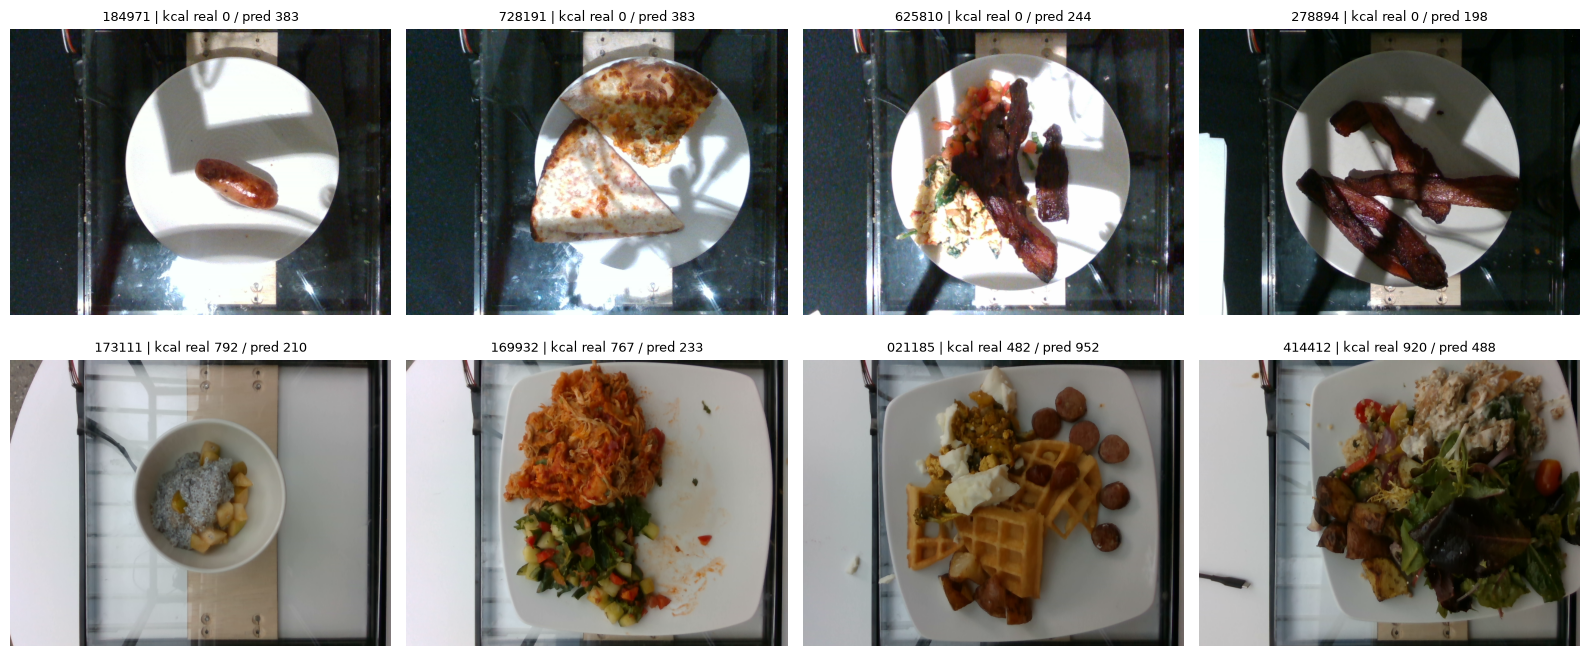

In [13]:
# ---- 1) Bootstrap pareado por plato: ¿las diferencias entre variantes son reales? ----
def pct_avg(y, yhat):
    return float((np.abs(y - yhat).mean(0) / y.mean(0) * 100).mean())

def boot_pair(name_a, name_b, mask=None, n_boot=2000, seed=0):
    pa = np.mean([r["pred"] for r in RESULTS[name_a]], axis=0)       # promedio de las 3 semillas
    pb = np.mean([r["pred"] for r in RESULTS[name_b]], axis=0)
    m = np.ones(len(YTE), bool) if mask is None else mask
    y, pa, pb = YTE[m], pa[m], pb[m]
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        d.append(pct_avg(y[i], pb[i]) - pct_avg(y[i], pa[i]))
    d = np.array(d)
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

names = [n for n, _ in EXPERIMENTS]
for a, b, que in [(0, 2, "CLIP frente a B1"), (1, 3, "DPT frente a sin profundidad"), (2, 3, "tabla frente a aprendida"),
                  (3, 4, "tabla + ajuste frente a tabla"), (3, 5, "profundidad real frente a DPT")]:
    m, lo, hi = boot_pair(names[a], names[b])
    print(f"{que:32s}: {m:+.2f} puntos de %MAE medio | IC95 [{lo:+.2f}, {hi:+.2f}]   (negativo = mejora)")

# ---- 2) ¿La profundidad del DPT trae la señal de altura? ----
Gm, Mm, GLm = GEO["model"]; Gg, _, GLg = GEO["gt"]
hp, hg = Gm[..., 1][Mm], Gg[..., 1][Mm]                      # altura media por región (cm)
print(f"\naltura media por región: corr DPT-real {np.corrcoef(hp, hg)[0, 1]:.2f} | sesgo {np.mean(hp - hg):+.2f} cm | "
      f"MAE {np.mean(np.abs(hp - hg)):.2f} cm | altura real mediana {np.median(hg):.2f} cm")
print(f"plano de la mesa: MAE {np.mean(np.abs(GLm[:, 0] - GLg[:, 0])):.2f} cm")
for nm, GL in (("DPT", GLm), ("real", GLg)):
    print(f"corr(volumen total {nm}, masa real) = {np.corrcoef(GL[:, 4], Y[:, 0])[0, 1]:.2f}")
print(f"corr(fracción de comida, masa real) = {np.corrcoef(GLm[:, 1], Y[:, 0])[0, 1]:.2f}   <- lo único que ve la variante sin profundidad")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(hg, hp, s=6, alpha=.4); lim = max(hg.max(), hp.max()); ax[0].plot([0, lim], [0, lim], "k--", lw=1)
ax[0].set_xlabel("altura media real (cm)"); ax[0].set_ylabel("altura media DPT (cm)"); ax[0].set_title("altura por región")
ax[1].scatter(GLg[:, 4], GLm[:, 4], s=6, alpha=.4); ax[1].set_xlabel("volumen total, prof. real"); ax[1].set_ylabel("volumen total, DPT")
ax[1].set_title("volumen del plato"); plt.tight_layout(); plt.show()

# ---- 3) Dónde falla: platos de ~0 kcal con predicción alta y sesgo de masa por tamaño ----
te = IDX["test"]; yh = best_run["pred"]
err = pd.DataFrame(dict(dish=[dishes[i] for i in te], grupo=GRP[te], kcal_real=YTE[:, 1], kcal_pred=yh[:, 1],
                        masa_real=YTE[:, 0], masa_pred=yh[:, 0], n_reg=A["n"][te]))
err["err_kcal"] = err.kcal_pred - err.kcal_real
err["sesgo_masa_pct"] = (err.masa_pred / err.masa_real - 1) * 100
err["error_masa_pct"] = (err.masa_pred - err.masa_real).abs() / err.masa_real * 100

bajos = err[err.kcal_real < 30].sort_values("kcal_pred", ascending=False)
print(f"\n{len(bajos)} platos con <30 kcal reales | su predicción mediana: {bajos.kcal_pred.median():.0f} kcal")
display(bajos.head(8).round(0))
peores = err.reindex(err.err_kcal.abs().sort_values(ascending=False).index).head(12)
display(peores.round(0))
g = err.groupby(pd.cut(err.masa_real, [0, 100, 200, 400, 2000]), observed=True)
display(pd.DataFrame(dict(n=g.size(), sesgo_pct=g.sesgo_masa_pct.mean(), error_pct=g.error_masa_pct.mean())).round(1))

sel = list(bajos.dish[:4]) + list(peores.dish[:4]); info = err.set_index("dish")
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a in ax.ravel(): a.axis("off")
for a, d in zip(ax.ravel(), sel):
    a.imshow(load_rgb(d)); a.set_title(f"{d[-6:]} | kcal real {info.loc[d, 'kcal_real']:.0f} / pred {info.loc[d, 'kcal_pred']:.0f}", fontsize=9)
plt.tight_layout(); plt.show()

In [14]:
# ---- A) Platos con etiqueta calórica inválida: masa > 0 pero kcal ≈ 0 (y comida visible) ----
BAD = (Y[:, 1] < 5) & (Y[:, 0] > 20)
print(f"{BAD.sum()} platos con kcal<5 y masa>20 g | en train: {BAD[IDX['train']].sum()} | en test: {BAD[IDX['test']].sum()}")
display(pd.DataFrame(Y[BAD], columns=TARGETS, index=np.array(dishes)[BAD]).round(1).head(15))   # ¿grasa, carb y proteína también en 0?

# para revisar a ojo (no se excluyen solos): densidad calórica casi imposible (>5.5 kcal/g)
ratio = Y[:, 1] / Y[:, 0]
rev = pd.DataFrame(Y, columns=TARGETS, index=dishes).assign(kcal_por_g=ratio)
display(rev[(Y[:, 0] > 20) & (ratio > 5.5)].round(2).head(15))

# ---- B) Reentrenar sin esos platos y evaluar con los targets inválidos enmascarados ----
if "IDX_ORIG" not in globals():                                  # evita pisar el original si repites la celda
    IDX_ORIG = {k: v.copy() for k, v in IDX.items()}
IDX["train"] = IDX_ORIG["train"][~BAD[IDX_ORIG["train"]]]
IDX["val"]   = IDX_ORIG["val"][~BAD[IDX_ORIG["val"]]]            # el test NO cambia: mismos platos y mismas filas de YTE

RESULTS = {}
for name, kw in EXPERIMENTS:
    RESULTS[name] = run_variant(**kw)

BAD_TE = BAD[IDX["test"]]
def metrics_masked(y, yhat, bad):
    """masa con todos los platos; kcal, grasa, carb y proteína solo con etiqueta válida. -> %MAE, MAE, mediana del error"""
    pct, mae, med = np.zeros(5), np.zeros(5), np.zeros(5)
    for k in range(5):
        m = np.ones(len(y), bool) if k == 0 else ~bad
        e = np.abs(y[m, k] - yhat[m, k])
        pct[k], mae[k], med[k] = e.mean() / y[m, k].mean() * 100, e.mean(), np.median(e)
    return pct, mae, med

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(aggregates(IDX["train"]), Y[IDX["train"]])
BASE = {"Media": np.tile(Y[IDX["train"]].mean(0), (len(YTE), 1)), "Ridge (agregados)": ridge.predict(aggregates(IDX["test"]))}

for sname, mask in subset_masks().items():
    rows, med_rows = {}, {}
    for k, p in BASE.items():
        pct, _, med = metrics_masked(YTE[mask], p[mask], BAD_TE[mask]); rows[k] = (pct, np.zeros(5)); med_rows[k] = med
    for name, runs in RESULTS.items():
        outs = [metrics_masked(YTE[mask], r["pred"][mask], BAD_TE[mask]) for r in runs]
        a = np.stack([o[0] for o in outs]); rows[name] = (a.mean(0), a.std(0))
        med_rows[name] = np.mean([o[2] for o in outs], axis=0)
    t = pd.DataFrame({k: [f"{m:.1f} ± {s:.1f}" if s > 0 else f"{m:.1f}" for m, s in zip(*v)] for k, v in rows.items()}, index=TARGETS).T
    t["promedio"] = [f"{np.mean(v[0]):.1f}" for v in rows.values()]
    t["mediana error masa (g)"] = [f"{v[0]:.0f}" for v in med_rows.values()]
    t["mediana error kcal"] = [f"{v[1]:.0f}" for v in med_rows.values()]
    print(f"\n=== %MAE con etiquetas inválidas enmascaradas · {sname} ({int(mask.sum())} platos, {int(BAD_TE[mask].sum())} sin kcal válida) ===")
    display(t)

139 platos con kcal<5 y masa>20 g | en train: 109 | en test: 15


,mass,kcal,fat,carb,protein
dish_1556575124,28.0,4.5,0.1,1.0,0.2
dish_1556575700,86.0,0.0,0.0,0.0,0.0
dish_1558640563,23.0,4.1,0.0,0.9,0.2
dish_1562008394,24.0,2.4,0.0,0.5,0.2
dish_1572974428,74.0,0.0,0.0,0.0,0.0
dish_1572464692,56.0,0.0,0.0,0.0,0.0
dish_1571931594,66.0,0.0,0.0,0.0,0.0
dish_1572887017,274.0,0.0,0.0,0.0,0.0
dish_1572984706,118.0,0.0,0.0,0.0,0.0
dish_1572453726,160.0,0.0,0.0,0.0,0.0


,mass,kcal,fat,carb,protein,kcal_por_g
dish_1558721757,133.0,768.869995,65.839996,30.190001,29.790001,5.78
dish_1559849412,61.0,352.640015,30.200001,13.850000,13.660000,5.78
dish_1558725403,50.0,289.049988,24.750000,11.350000,11.200000,5.78
dish_1558549413,118.0,682.159973,58.410000,26.790001,26.430000,5.78
dish_1558378553,68.0,393.109985,33.660000,15.440000,15.230000,5.78
dish_1558550127,22.0,127.180000,10.890000,4.990000,4.930000,5.78
dish_1558722068,31.0,179.210007,15.340000,7.040000,6.940000,5.78
dish_1558461692,40.0,231.240005,19.799999,9.080000,8.960000,5.78
dish_1558723847,96.0,554.979980,47.520000,21.790001,21.500000,5.78
dish_1558379182,56.0,323.739990,27.719999,12.710000,12.540000,5.78



=== %MAE con etiquetas inválidas enmascaradas · test completo (261 platos, 15 sin kcal válida) ===


,mass,kcal,fat,carb,protein,promedio,mediana error masa (g),mediana error kcal
Media,55.8,66.9,82.9,64.0,85.2,71.0,98,146
Ridge (agregados),30.8,49.4,70.6,55.7,65.1,54.3,46,95
1. B1 · DPT · aprendida (pipeline anterior),26.0 ± 0.2,29.2 ± 0.2,43.8 ± 0.2,41.2 ± 0.3,42.8 ± 0.5,36.6,35,42
2. CLIP · sin profundidad · tabla,21.1 ± 0.1,25.2 ± 0.0,33.8 ± 0.3,32.3 ± 0.1,35.5 ± 0.4,29.6,27,30
3. CLIP · DPT · aprendida,25.1 ± 0.5,24.7 ± 0.1,34.2 ± 0.3,29.7 ± 0.2,34.0 ± 0.3,29.5,36,33
4. CLIP · DPT · tabla,20.9 ± 0.4,25.0 ± 0.2,33.2 ± 0.3,31.9 ± 0.3,35.9 ± 0.5,29.4,28,31
5. CLIP · DPT · tabla + ajuste,20.6 ± 0.5,24.7 ± 0.2,31.7 ± 0.4,31.6 ± 0.6,33.3 ± 0.3,28.4,25,32
6. CLIP · prof. real · tabla (cota superior),17.5 ± 0.5,21.3 ± 0.9,30.5 ± 0.6,28.8 ± 0.7,32.8 ± 0.1,26.2,23,25



=== %MAE con etiquetas inválidas enmascaradas · solo set limpio (40 platos, 1 sin kcal válida) ===


,mass,kcal,fat,carb,protein,promedio,mediana error masa (g),mediana error kcal
Media,45.1,49.7,61.7,53.8,67.3,55.5,100,115
Ridge (agregados),23.8,43.6,66.2,43.2,67.7,48.9,46,116
1. B1 · DPT · aprendida (pipeline anterior),20.6 ± 0.7,27.9 ± 0.8,48.7 ± 0.8,33.1 ± 0.5,43.7 ± 0.5,34.8,37,55
2. CLIP · sin profundidad · tabla,14.4 ± 0.6,28.7 ± 0.3,38.5 ± 0.5,27.4 ± 0.5,37.5 ± 0.7,29.3,34,58
3. CLIP · DPT · aprendida,20.3 ± 1.1,26.7 ± 0.5,39.2 ± 0.2,26.8 ± 0.6,35.9 ± 0.8,29.8,47,45
4. CLIP · DPT · tabla,14.2 ± 0.6,30.4 ± 0.7,39.8 ± 0.9,28.5 ± 0.3,39.6 ± 0.7,30.5,33,56
5. CLIP · DPT · tabla + ajuste,14.2 ± 0.5,30.5 ± 1.1,38.7 ± 0.8,28.5 ± 1.2,37.8 ± 1.2,29.9,30,64
6. CLIP · prof. real · tabla (cota superior),12.7 ± 0.8,26.5 ± 1.6,36.6 ± 1.6,25.0 ± 1.5,33.7 ± 0.7,26.9,30,48


In [15]:
def boot_pair_masked(name_a, name_b, target=None, mask=None, n_boot=2000, seed=0):
    """Bootstrap por plato de (%MAE de B) - (%MAE de A) con etiquetas inválidas enmascaradas. target: índice 0..4 o None = promedio."""
    pa = np.mean([r["pred"] for r in RESULTS[name_a]], axis=0)
    pb = np.mean([r["pred"] for r in RESULTS[name_b]], axis=0)
    m = np.ones(len(YTE), bool) if mask is None else mask
    y, pa, pb, bad = YTE[m], pa[m], pb[m], BAD_TE[m]
    stat = (lambda v: v.mean()) if target is None else (lambda v: v[target])
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        d.append(stat(metrics_masked(y[i], pb[i], bad[i])[0]) - stat(metrics_masked(y[i], pa[i], bad[i])[0]))
    d = np.array(d)
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

names = [n for n, _ in EXPERIMENTS]
for a, b, que, tg in [(0, 2, "CLIP frente a B1", None), (1, 3, "DPT frente a sin profundidad", None),
                      (2, 3, "tabla frente a aprendida (promedio)", None), (2, 3, "tabla frente a aprendida (solo masa)", 0),
                      (3, 4, "tabla + ajuste frente a tabla", None), (3, 5, "profundidad real frente a DPT", None)]:
    m, lo, hi = boot_pair_masked(names[a], names[b], target=tg)
    print(f"{que:38s}: {m:+.2f} puntos | IC95 [{lo:+.2f}, {hi:+.2f}]   (negativo = mejora)")

CLIP frente a B1                      : -7.04 puntos | IC95 [-9.53, -4.70]   (negativo = mejora)
DPT frente a sin profundidad          : -0.24 puntos | IC95 [-0.81, +0.35]   (negativo = mejora)
tabla frente a aprendida (promedio)   : -0.19 puntos | IC95 [-1.58, +1.22]   (negativo = mejora)
tabla frente a aprendida (solo masa)  : -4.28 puntos | IC95 [-6.13, -2.36]   (negativo = mejora)
tabla + ajuste frente a tabla         : -1.01 puntos | IC95 [-1.49, -0.55]   (negativo = mejora)
profundidad real frente a DPT         : -3.66 puntos | IC95 [-4.89, -2.47]   (negativo = mejora)


## 11. Cómo leer los resultados y qué falta

**Orden de lectura**
1. **Variante 4 frente a Media y Ridge:** si no los supera con claridad, la cabeza no aporta.
2. **1 → 3:** cuánto mejoró la cabeza CLIP frente a las clases de B1. Es el efecto de todo el trabajo de autoetiquetado y fine‑tuning.
3. **2 → 4:** cuánto aporta la profundidad. Si es poco, revisa las unidades de profundidad (la mediana debería salir cerca de 0.3–0.4 m) y que el DPT esté bien cargado.
4. **3 → 4:** tabla real frente a aprendida. Si `learned` gana, la tabla no calza con cómo se cocinó o midió esa comida (mira qué clases no se encontraron por nombre).
5. **4 → 6:** costo de usar la profundidad predicha en lugar de la real. Es lo que cuesta no tener `depth_raw.png`.

**Limitaciones (honestas)**
- **Solo hay verdad de terreno por plato**, no por región. Los gramos por región se validan solo a través de su suma; revisa a ojo la tabla de `predict_photo` en varios platos.
- **El set limpio es pequeño** (decenas de platos). Úsalo como orientación, no como cifra final.
- **Sin `DPT_SPLIT_FILE`** el test puede mezclar platos con los que se entrenó el DPT y la profundidad se ve mejor de lo que será en fotos nuevas.
- **Dominio:** todo el entrenamiento y la prueba usan fotos cenitales de la cafetería de Nutrition5k. Con fotos de celular de comida colombiana habrá que validar aparte.
- **Tabla nutricional:** la tabla trae kcal por gramo de cada ingrediente tal como se registró en Nutrition5k; clases fusionadas o sin coincidencia por nombre usan una aproximación.

siguientes pasos naturales
- Si el efecto de la profundidad real frente a la predicha es grande, mejorar o reentrenar el DPT.
- Si la clase sigue siendo el cuello de botella, la Parte 7 del notebook de fine‑tuning (afinar B1) o más etiquetado de las clases débiles.
- Reentrenar esta cabeza con la cabeza CLIP definitiva y mapear las clases a la tabla nutricional de tu app.
